Немного полезных функций

Загрузка данных из файла. Тут две полезные конструкции. 
Первая, это построчное чтение реализованное с помощью
~~~
for line in open(path+'/movies.dat'):
~~~
Вторая -- функция split(), позволяющая разделить строку, по символу или последовательности символов в качестве разделителя.


In [56]:
#Чтение данных

def loadMovieLens1M(path='./ml-1m'):
# Получить названия фильмов
    movies={}
    for line in open(path+'/movies.dat', encoding="cp1251"):
        (id,title)=line.split('::')[0:2] #при желании тут можно добавить чтение жанров.
        movies[id]=title
# Загрузить данные
    prefs={}
    for line in open(path+'/ratings.dat', encoding="cp1251"):
        (user,movieid,rating,ts)=line.split('::')
        prefs.setdefault(user,{})
        prefs[user][movies[movieid]]=float(rating)
    return prefs

In [57]:
def loadMovieLens(path='./ml-latest-small'):
# Получить названия фильмов
    movies={}
    skip_first = True
    for line in open(path+'/movies.csv', encoding='utf-8'):
        if skip_first:
            skip_first = False
            continue
        (id,title)=line.split(',')[0:2]
        movies[id]=title
# Загрузить данные
    prefs={}
    skip_first = True
    for line in open(path+'/ratings.csv', encoding='utf-8'):
        if skip_first:
            skip_first = False
            continue
        (user,movieid,rating,ts)=line.split(',')
        prefs.setdefault(user,{})
        prefs[user][movies[movieid]]=float(rating)
    return prefs

In [58]:
%%time
critics = loadMovieLens1M()

CPU times: total: 500 ms
Wall time: 506 ms


In [59]:
%%time
critics = loadMovieLens()

CPU times: total: 78.1 ms
Wall time: 73.4 ms


In [5]:
len(critics)

610

Тестовая и обучающая выборки.
Рассмотрим выбор или не выбор элемента с заданной вероятностью, для этого нам понадобится модуль random и функция random(). Последняя возвращает случайное число равномерно распределенное в диапазоне от 0 до 1. Этим удобно пользоваться, чтобы получить случайное событие с вероятностью alpha достаточно использовать конструкцию 
~~~
if random()<alpha:
~~~

Функция seed() инициализирует генератор псевдослучайных чисел заданным числом. Это позволяет воспроизводить идентичную последовательность случайных значений при последовательных запусков. Очень полезно при отладке.

In [6]:
from random import random, seed
seed(100)
print(random(), random(), random())
print(random(), random(), random())
seed(100)
print(random(), random(), random())


0.1456692551041303 0.45492700451402135 0.7707838056590222
0.705513226934028 0.7319589730332557 0.43351443489540376
0.1456692551041303 0.45492700451402135 0.7707838056590222


In [7]:
print(random(), random(), random())

0.705513226934028 0.7319589730332557 0.43351443489540376


Отберем, например, около 2 процентов пользователей:

In [8]:
seed(20)
user_list = [u for u in critics if random()<1.02]

In [9]:
len(user_list)

610

In [10]:
sub_movies = {}
for u in user_list:
    for item in critics[u]:
        if not item in sub_movies:
            sub_movies[item] = 0
        sub_movies[item] += 1
            

In [11]:
dict(list(sub_movies.items())[:10])

{'Toy Story (1995)': 215,
 'Grumpier Old Men (1995)': 52,
 'Heat (1995)': 102,
 'Seven (a.k.a. Se7en) (1995)': 203,
 '"Usual Suspects': 204,
 'From Dusk Till Dawn (1996)': 55,
 'Bottle Rocket (1996)': 23,
 'Braveheart (1995)': 237,
 'Rob Roy (1995)': 44,
 'Canadian Bacon (1995)': 11}

Оставим только фильмы которые оценило хотя бы 5 человек

In [12]:
movie5 = [m for m in sub_movies if sub_movies[m]>4]

In [13]:
len(movie5)

3628

In [14]:
movie5_sublist = [m for m in movie5 if random()<1.1]

In [15]:
len(movie5_sublist)

3628

In [16]:
131*167

21877

In [17]:
sub_critics = {}
for u in user_list:
    sub_critics[u] = {}
    for m in critics[u]:
        if m in movie5_sublist:
            sub_critics[u][m] = critics[u][m]

In [18]:
{user: dict(list(ratings.items())[:3])
 for user, ratings in list(sub_critics.items())[:3]}

{'1': {'Toy Story (1995)': 4.0,
  'Grumpier Old Men (1995)': 4.0,
  'Heat (1995)': 4.0},
 '2': {'"Shawshank Redemption': 3.0,
  'Tommy Boy (1995)': 4.0,
  'Good Will Hunting (1997)': 4.5},
 '3': {'Dangerous Minds (1995)': 0.5,
  "Schindler's List (1993)": 0.5,
  'Courage Under Fire (1996)': 0.5}}

попробуем простейший вариант стохастического градиентного спуска

In [19]:
seed(6660)
L = 5
Pi = {}
Bi = {}
for u in user_list:
    Bi[u] = 0
    Pi[u] = []
    for i in range(L):
        Pi[u].append(random())
Ba = {}
Qa = {}        
for m in movie5_sublist:
    Ba[m] = 0 
    Qa[m] = []
    for i in range(L):
        Qa[m].append(random())


In [20]:
rating_list = []
for u in sub_critics:
    for m in sub_critics[u]:
        rating_list.append((u,m))

In [21]:
len(rating_list)

90236

In [22]:
def evaluate_ratings(rating_list, critics, Pi, Qa, Bi, Ba, L = 5):
    summ = 0
    for (u,m) in rating_list:
        rate = Bi[u] + Ba[m]
        for i in range(L):
            rate += Pi[u][i]*Qa[m][i]
        summ += (critics[u][m] - rate)*(critics[u][m] - rate)
    return (summ/len(rating_list))**0.5
        

In [23]:
evaluate_ratings(rating_list, sub_critics, Pi, Qa, Bi, Ba, L = 5)

2.6061931667284055

In [24]:
evaluate_ratings(rating_list, sub_critics, Pi, Qa, Bi, Ba, L = 5)

2.6061931667284055

In [25]:
gamma = 0.01

In [26]:
p40_1 = []
p40_2 = []

In [27]:
%%time
for jjj in range(10):
    for (u, m) in rating_list:
    #one step of gradient
        rate = Bi[u] + Ba[m]
        for i in range(L):
            rate += Pi[u][i]*Qa[m][i]
        error = rate - sub_critics[u][m]
        deltaBi = gamma*error     
        deltaBa = gamma*error     
        Bi[u] -= deltaBi
        Ba[m] -= deltaBa
        for i in range(L):
            deltaPi = (gamma*error*Qa[m][i])
            deltaQa = (gamma*error*Pi[u][i])
            Pi[u][i] -= deltaPi
            Qa[m][i] -= deltaQa
    p40_1.append(Pi["40"][1])
    p40_2.append(Pi["40"][2])
print(evaluate_ratings(rating_list, sub_critics, Pi, Qa, Bi, Ba, L = 5))

0.8130579626614378
CPU times: total: 2.31 s
Wall time: 2.31 s


In [28]:
evaluate_ratings(rating_list, sub_critics, Pi, Qa, Bi, Ba, L = 5)

0.8130579626614378

In [29]:
import seaborn as sns

In [30]:
x = [i for i in range(len(p40_1))]
p40_1[:10]


[1.2783316913247347,
 1.0321382729741952,
 1.101160753947988,
 1.1133659063525256,
 1.115139041945451,
 1.1134632707485794,
 1.1108148534071378,
 1.1084654157797478,
 1.1071819574117558,
 1.1074584106838736]

<Axes: >

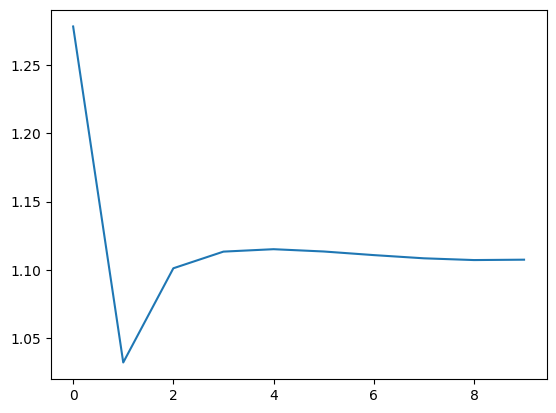

In [31]:
sns.lineplot(x = x[0:len(p40_1)], y=p40_1[0:len(p40_1)])


<Axes: >

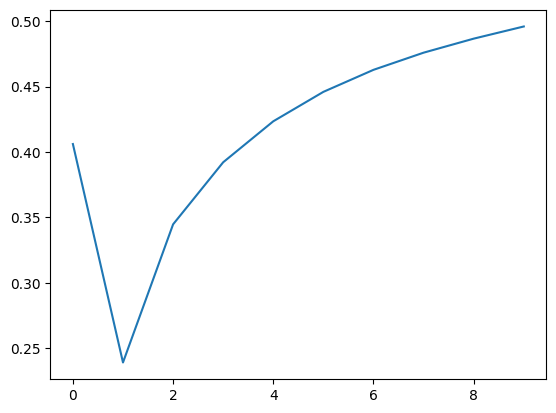

In [32]:
sns.lineplot(x = x[:100], y=p40_2[:100])

In [33]:
Pi['40']

[0.6490651420841653,
 1.1074584106838736,
 0.49587539337627184,
 1.0046598964755158,
 1.2229661459803272]

In [34]:
dict(list(Qa.items())[:2])

{'Toy Story (1995)': [0.2393505484556964,
  0.3423906328760685,
  0.36457973988473424,
  0.6812822341213733,
  0.8149652424061777],
 'Grumpier Old Men (1995)': [0.28872510269157947,
  0.4593096901954916,
  0.23531681678310493,
  0.7031877013696803,
  0.6264121561747429]}

In [35]:
movies_sorted_by_1 = sorted([m for m in Qa], key = lambda x:Qa[x][1])

In [36]:
movies_sorted_by_1[:5]

["Look Who's Talking Too (1990)",
 'Pokémon the Movie 2000 (2000)',
 'Eye of the Beholder (1999)',
 'Mr. & Mrs. Smith (2005)',
 'High School High (1996)']

In [37]:
movies_sorted_by_1[-5:]

['"English Patient',
 'Seven Samurai (Shichinin no samurai) (1954)',
 'Last Tango in Paris (Ultimo tango a Parigi) (1972)',
 'Nausicaä of the Valley of the Wind (Kaze no tani no Naushika) (1984)',
 'Black Swan (2010)']

In [38]:
movies_sorted_by_2 = sorted([m for m in Qa], key = lambda x:Qa[x][2])

In [39]:
movies_sorted_by_2[:5]

['Dumb and Dumberer: When Harry Met Lloyd (2003)',
 'Enemy of the State (1998)',
 '"Master of Disguise',
 'Twilight (2008)',
 'Clash of the Titans (2010)']

In [40]:
movies_sorted_by_3 = sorted([m for m in Qa], key = lambda x:Qa[x][3])

In [41]:
movies_sorted_by_3[:5]

['"Flintstones in Viva Rock Vegas',
 '"Blair Witch Project',
 'Mortal Kombat (1995)',
 'Grease 2 (1982)',
 '"13th Warrior']

Упражнения из исходного ноутбука

### Задание 1. Baseline-модель

Сложите общую оценку, смещение пользователя и смещение фильма. Обучите только смещения и сравните RMSE с полной SVD-моделью. Попробуйте разные значения общей оценки и проверьте, подходит ли средний рейтинг.

### Задание 2. Влияние числа факторов

Обучите модель с 2, 5, 10, 20 и 50 факторами. Постройте график итогового RMSE. Посмотрите, где начинается переобучение и что происходит при дальнейшем росте числа факторов.

### Задание 3. Скорость обучения

Попробуйте шаги 0,001, 0,005, 0,01 и 0,05. Для каждого постройте график RMSE по эпохам. Проверьте, расходится ли обучение при большом шаге.

### Задание 4. Train/test split

Оставьте 80% оценок для обучения и 20% для теста. На тесте возьмите квадратный корень из средней квадратичной ошибки. Посмотрите, как меняется переобучение при росте числа факторов.

### Задание 5. L2-регуляризация

При каждом обновлении фактора вычитайте из приращения сам фактор, умноженный на шаг обучения и коэффициент штрафа. Сделайте это для факторов пользователей и фильмов. Попробуйте штрафы 0,01, 0,1 и 0,5 и сравните тестовый RMSE.

### Задание 6. Early stopping

Остановите обучение, если ошибка на валидации растёт несколько эпох подряд. Сравните с запуском на 100 эпох и посчитайте, сколько эпох удалось сэкономить.

### Задание 7. Momentum

Возьмите 90% предыдущего обновления, прибавьте градиент, умноженный на шаг, и вычтите результат из параметров. Сравните графики RMSE с обычным SGD.

# Домашнее задание 1. Baseline, SVD и ALS

Беру оценки из sub_critics и делю их на train и test. Внутри train выделяю часть для подбора настроек. Итоговые модели сравниваю на одном test.

Условие random() < 1.02 пропускает всех пользователей. Оставляю эту выборку как в примере.

In [42]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit
from scipy import sparse
from scipy.sparse.linalg import lsqr, spsolve
from threadpoolctl import threadpool_limits

# Для небольших систем ALS хватит одного потока BLAS.
blas_limit = threadpool_limits(limits = 1, user_api="blas")
SEED = 42

def ratings_frame(preferences):
    frame = pd.DataFrame(
        [(user, movie, rating) for user, movies in preferences.items()
         for movie, rating in movies.items()],
        columns=["user", "movie", "rating"],
    )
    frame["u"], user_ids = pd.factorize(frame["user"])
    frame["i"], movie_ids = pd.factorize(frame["movie"])
    return frame, user_ids, movie_ids


ratings, users, movies = ratings_frame(sub_critics)
n_users, n_movies = len(users), len(movies)

order = np.random.default_rng(SEED).permutation(len(ratings))
cut = int(0.8 * len(order))
train = ratings.iloc[order[:cut]]
test = ratings.iloc[order[cut:]]

val_cut = int(0.8 * len(train))
fit_train = train.iloc[:val_cut]
val = train.iloc[val_cut:]

# Валидация нужна для подбора настроек.
print(f"{n_users} пользователей, {n_movies} фильмов")
print(f"Train: {len(train)}, test: {len(test)}, validation внутри train: {len(val)}")

610 пользователей, 3628 фильмов
Train: 72188, test: 18048, validation внутри train: 14438


In [43]:
def rating_arrays(data):
    return data["u"].to_numpy(),data["i"].to_numpy(), data["rating"].to_numpy()


def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))


def model_rmse(data, model):
    u, i, r = data
    mu, b_u, b_i, P, Q = model
    predicted = mu + b_u[u] + b_i[i] + np.einsum("ij,ij->i", P[u], Q[i])
    return rmse(r, predicted)

## I. Baseline через МНК

### 1.1. Обучение

Прогноз состоит из общей оценки и двух поправок — на пользователя и фильм. Это линейная регрессия. Признаки показывают, кто поставил оценку и какому фильму. Целевая переменная — сама оценка. Для MovieLens 1M получается 9747 параметров.

При ненулевом штрафе решаю нормальные уравнения. При нулевом штрафе у задачи несколько решений из-за зависимости столбцов, поэтому использую LSQR.

In [44]:
def fit_baseline(sub_critics,  lambda_reg =10):
    user_count, movie_count = n_users, n_movies
    if isinstance(sub_critics, dict):
        sub_critics, user_ids, movie_ids = ratings_frame(sub_critics)
        user_count, movie_count = len(user_ids), len(movie_ids)
    u, i, r = rating_arrays(sub_critics)
    rows = np.tile(np.arange(len(r)),3)
    cols = np.concatenate([np.zeros(len(r),  dtype=int), 1 + u, 1 + user_count + i])
    X = sparse.csr_matrix(
        (np.ones(len(cols)), (rows, cols)),
        shape=(len(r), 1 + user_count + movie_count),
    )

    if lambda_reg == 0:
        theta = lsqr(X, r, atol=1e-10, btol=1e-10)[0]
        # Центрирую смещения только для известных пользователей и фильмов.
        for columns in (1 + np.unique(u), 1 + user_count + np.unique(i)):
            shift = theta[columns].mean()
            theta[columns] -= shift
            theta[0] += shift
    else:
        penalty = np.full(X.shape[1], lambda_reg, dtype=float)
        penalty[0] = 0
        theta = spsolve(X.T @ X + sparse.diags(penalty, format="csc"), X.T @ r)

    return theta[0], theta[1:1 + user_count], theta[1 + user_count:]


def baseline_rmse(data, model):
    u, i, r = rating_arrays(data)
    mu, b_u, b_i = model
    return rmse(r, mu + b_u[u] + b_i[i])


mu, b_u, b_i = fit_baseline(train)
print(f"Train RMSE: {baseline_rmse(train, (mu, b_u, b_i)):.4f}")

Train RMSE: 0.8281


### 1.2. Смещения пользователей и фильмов

Сравниваю смещения модели с тем, насколько средние оценки пользователя и фильма отличаются от среднего по train.

In [45]:
def bias_table(data, key,ids, biases, index_name):
    table = data.groupby(key)["rating"].agg(["size", "mean"])
    table.columns = ["Оценок", "Средняя оценка"]
    table["Смещение"] = biases[table.index]
    table["Средняя минус общая"] = table["Средняя оценка"] - data["rating"].mean()
    table.index = ids[table.index].rename(index_name)
    return table


def top_and_bottom(table, top_label, bottom_label):
    return pd.concat(
        [table.nlargest(3, "Смещение"), table.nsmallest(3, "Смещение")],
        keys=[top_label, bottom_label],
    ).round(3)


user_table = bias_table(train, "u", users, b_u, "Пользователь")
display(top_and_bottom(user_table, "Добрые", "Злые"))

movie_table = bias_table(train, "i", movies, b_i, "Фильм")
display(top_and_bottom(movie_table[movie_table["Оценок"] >= 10], "Лучшие", "Худшие"))

Оценок  Средняя оценка  Смещение  Средняя минус общая
       Пользователь                                                       
Добрые 43                93           4.527     1.012                0.989
       452              160           4.591     0.930                1.053
       53                16           5.000     0.872                1.462
Злые   153              124           2.210    -1.376               -1.328
       442               17           1.382    -1.372               -2.155
       139              155           2.135    -1.360               -1.402

Оценок  \
       Фильм                                                        
Лучшие "Shawshank Redemption                                  247   
       Wallace & Gromit: The Best of Aardman Animation...      22   
       Dr. Strangelove or: How I Learned to Stop Worry...      74   
Худшие Godzilla (1998)                                         28   
       Spice World (1997)                                      10   
       Speed 2: Cruise Control (1997)                          16   

                                                           Средняя оценка  \
       Фильм                                                                
Лучшие "Shawshank Redemption                                        4.437   
       Wallace & Gromit: The Best of Aardman Animation...           4.500   
       Dr. Strangelove or: How I Learned to Stop Worry...           4.304   
Худшие Godzilla (1998)                                              1.875   
       Spice World (1997)                                           1.350   
       Speed 2: Cruise Control (1997)                               1.656   

                                                           Смещение  \
       Фильм                                                          
Лучшие "Shawshank Redemption                                  0.894   
       Wallace & Gromit: The Best of Aardman Animation...     0.781   
       Dr. Strangelove or: How I Learned to Stop Worry...     0.781   
Худшие Godzilla (1998)                                       -1.036   
       Spice World (1997)                                    -1.013   
       Speed 2: Cruise Control (1997)                        -1.001   

                                                           Средняя минус общая  
       Фильм                                                                    
Лучшие "Shawshank Redemption                                             0.899  
       Wallace & Gromit: The Best of Aardman Animation...                0.962  
       Dr. Strangelove or: How I Learned to Stop Worry...                0.766  
Худшие Godzilla (1998)                                                  -1.663  
       Spice World (1997)                                               -2.188  
       Speed 2: Cruise Control (1997)                                   -1.882

У пользователя 53 средняя оценка 5,0. Это на 1,462 выше общего среднего, а модель дала смещение 0,872. У фильма Spice World разница средних −2,188, а смещение −1,013. Модель учитывает, кому и за какие фильмы ставили оценки. Штраф тоже уменьшает смещения, особенно при малом числе оценок.

Названия взяты из sub_critics. Загрузчик обрезает названия с запятой. Первая строка таблицы — The Shawshank Redemption (1994).

### 1.3. Регуляризация и вклад смещений

,λ,Train RMSE,Test RMSE
0,0.0,0.8047,0.8604
1,0.1,0.8047,0.8596
2,1.0,0.8058,0.8558
3,10.0,0.8281,0.8615
4,100.0,0.9007,0.9160
5,1000.0,0.9836,0.9938


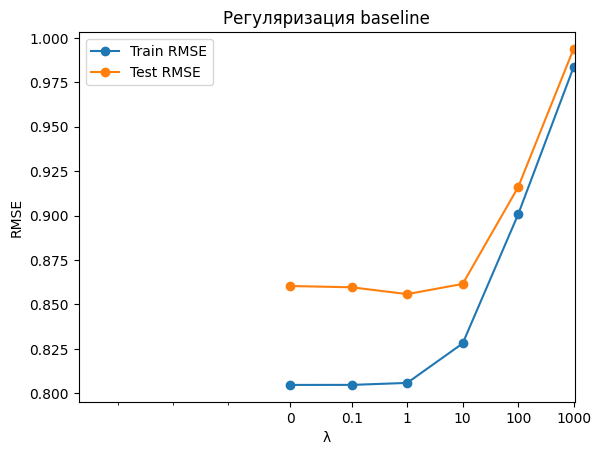

,Naive,User-bias,Full baseline
Train,1.0279,0.9407,0.8281
Test,1.0378,0.9513,0.8615


,User-bias,Full baseline
Train,0.0872,0.1127
Test,0.0866,0.0897


In [46]:
baseline_regs= [0, 0.1, 1, 10, 100, 1000]
baseline_rows = []
for reg in baseline_regs:
    model = fit_baseline(train, reg)
    baseline_rows.append([reg, baseline_rmse(train, model), baseline_rmse(test, model)])

baseline_scores = pd.DataFrame(baseline_rows, columns=["λ", "Train RMSE", "Test RMSE"])
display(baseline_scores.round(4))
baseline_scores.plot(x="λ", marker="o", ylabel="RMSE", title="Регуляризация baseline")
plt.xscale("symlog", linthresh=0.1)
plt.xticks(baseline_regs, [str(reg) for reg in baseline_regs])
plt.show()

ablation = []
train_mean = train["rating"].mean()
for data in (train, test):
    u, i, r = rating_arrays(data)
    user_pred = mu + b_u[u]
    ablation.append([rmse(r, train_mean), rmse(r, user_pred), rmse(r, user_pred + b_i[i])])

ablation = pd.DataFrame(ablation, index=["Train", "Test"],
                        columns=["Naive", "User-bias", "Full baseline"])
display(ablation.round(4))
display((-ablation.diff(axis=1).iloc[:, 1:]).round(4))

С нулевым штрафом ошибка на train самая низкая: 0,8047. На test лучше штраф 1 с ошибкой 0,8558. Слабый штраф хуже защищает от переобучения, а сильный убирает даже полезные смещения. Поэтому ошибка на test сначала падает, потом растёт.

В сравнении при штрафе 10 среднее по train даёт 1,0378 на test. Поправка на пользователя снижает ошибку до 0,9513, а поправка на фильм — до 0,8615.

## II. SVD через SGD

### 2.1. Разбиение и число факторов

Один раз считаю среднюю оценку по train. На каждой оценке обновляю смещения и факторы пользователя и фильма. Для обоих факторов беру их значения до обновления. Numba ускоряет цикл по оценкам.

In [47]:
def init_factors(data,n_factors, rng):
    u, i, r = data
    P = rng.normal(0, 0.01, size=(n_users, n_factors))
    Q = rng.normal(0, 0.01, size=(n_movies, n_factors))
    P[np.bincount(u, minlength=n_users) == 0] = 0
    Q[np.bincount(i, minlength=n_movies) == 0] = 0
    return r.mean(), np.zeros(n_users), np.zeros(n_movies), P, Q


@njit
def sgd_epoch(u, i, r, order, model, gamma, reg):
    mu, b_u, b_i, P, Q = model
    for k in order:
        user, movie = u[k], i[k]
        predicted = mu + b_u[user] + b_i[movie]
        for j in range(P.shape[1]):
            predicted += P[user, j] * Q[movie, j]
        error = r[k] - predicted
        b_u[user] += gamma * (error - reg * b_u[user])
        b_i[movie] += gamma * (error - reg * b_i[movie])
        # Оба вектора обновляю по старым значениям.
        for j in range(P.shape[1]):
            p, q = P[user, j], Q[movie, j]
            P[user, j] += gamma * (error * q - reg * p)
            Q[movie, j] += gamma * (error * p - reg * q)


def train_sgd(train, n_factors=20, n_epochs=100, gamma=0.01, reg=0,
              test=None, history=None):
    data = rating_arrays(train)
    rng = np.random.default_rng(SEED)
    model = init_factors(data, n_factors, rng)
    if history is not None:
        test_data = rating_arrays(test)

    for _ in range(n_epochs):
        sgd_epoch(*data, rng.permutation(len(train)), model, gamma, reg)
        if history is not None:
            history.append([model_rmse(data, model), model_rmse(test_data, model)])
    return model


def learning_curve(trainer, train, test, **params):
    history = []
    trainer(train, test=test, history=history, **params)
    return pd.DataFrame(history, index=pd.RangeIndex(1, len(history) + 1, name="Эпоха"),
                        columns=["Train RMSE", "Test RMSE"])


def sweep(trainer, train, test, param, values, **fixed):
    curves = {}
    for value in values:
        params = {**fixed, param: value}
        curves[value] = learning_curve(trainer, train, test, **params)
    scores = pd.DataFrame({value: curve.iloc[-1] for value, curve in curves.items()}).T
    return scores.rename_axis(param), curves

,Train RMSE,Test RMSE
n_factors,,
0,0.8281,0.8615
2,0.7052,0.8866
5,0.6067,0.9410
10,0.4869,1.0022
20,0.3271,1.0608
50,0.1064,1.0122
100,0.0352,0.9231


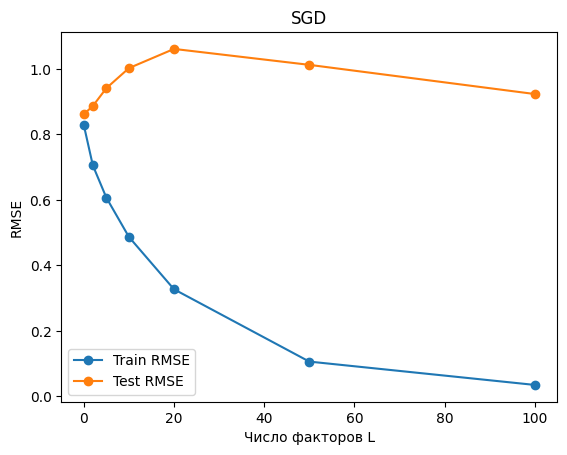

In [48]:
sgd_ranks = [2, 5, 10, 20, 50, 100]
sgd_rank_scores, _ = sweep(train_sgd, train,  test, "n_factors", sgd_ranks)
baseline = mu, b_u, b_i
rank_scores = sgd_rank_scores.copy()
rank_scores.loc[0] = [baseline_rmse(train, baseline), baseline_rmse(test, baseline)]
rank_scores = rank_scores.sort_index()
display(rank_scores.round(4))
rank_scores.plot(marker="o", xlabel="Число факторов L", ylabel="RMSE", title="SGD")
plt.show()

С ростом числа факторов векторы становятся длиннее, а параметров больше. Это помогает подогнать train. Когда число факторов больше размеров матрицы, её возможный ранг уже не растёт. Сами значения в векторах расти не обязаны.

При двух факторах RMSE на train равен 0,7052, при ста — 0,0352. На test без штрафа лучший факторный вариант — два фактора с RMSE 0,8866. Baseline без факторов здесь лучше. Ниже проверяю, помогает ли L2.

### 2.2. Скорость обучения

,Train RMSE,Test RMSE
gamma,,
0.001,0.8170,0.8579
0.005,0.5460,0.9312
0.010,0.4869,1.0022
0.050,0.4720,1.1315
0.100,0.5432,1.0759


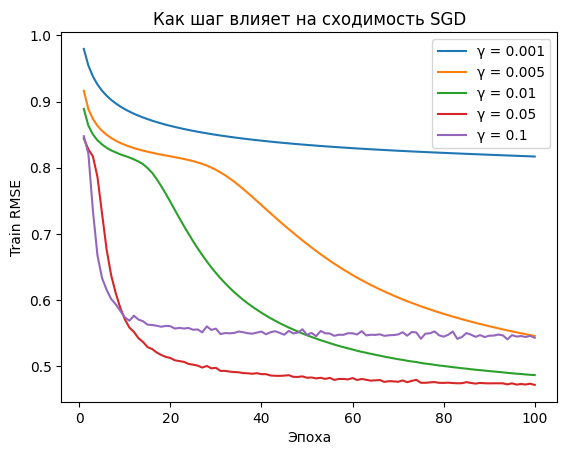

In [49]:
gammas = [0.001, 0.005, 0.01, 0.05, 0.1]
sgd_gamma_scores, sgd_gamma_curves = sweep(
    train_sgd, train, test, "gamma", gammas, n_factors =10,
)
display(sgd_gamma_scores.round(4))
for gamma, curve in sgd_gamma_curves.items():
    plt.plot(curve.index, curve["Train RMSE"], label=f"γ = {gamma}")
plt.gca().set(xlabel="Эпоха", ylabel="Train RMSE", title="Как шаг влияет на сходимость SGD")
plt.legend()
plt.show()

Шаг 0,05 быстро снижает ошибку на train до 0,4720. При шаге 0,1 ошибка сначала падает быстрее, а потом колеблется около 0,55. Такой шаг слишком крупный для стабильных обновлений. Обучение в этом запуске не разошлось.

### 2.3. L2-регуляризация

На каждом шаге L2 тянет смещения и факторы к нулю.

,Train RMSE,Test RMSE
reg,,
0.000,0.3271,1.0608
0.001,0.3282,1.0443
0.010,0.3454,0.9726
0.100,0.6152,0.8398
0.500,0.8326,0.8722


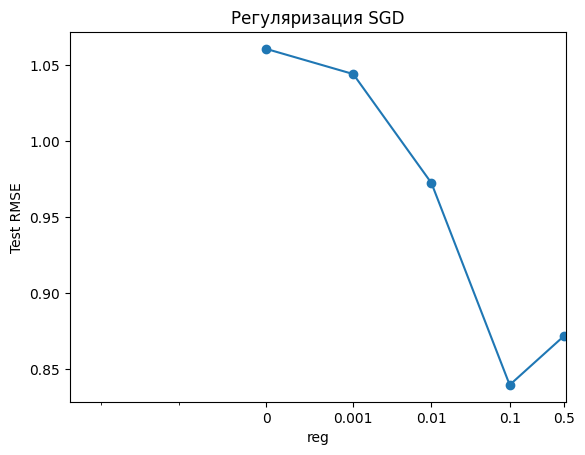

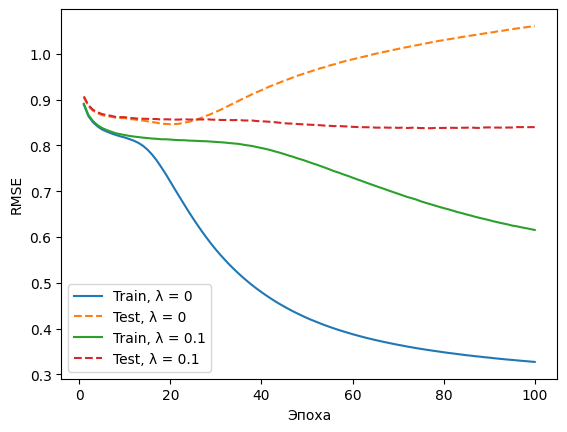

In [50]:
sgd_regs = [0, 0.001, 0.01, 0.1, 0.5]
sgd_reg_scores, sgd_reg_curves = sweep(
    train_sgd, train, test, "reg", sgd_regs, n_factors= 20,
)
display(sgd_reg_scores.round(4))
sgd_reg_scores["Test RMSE"].plot(marker="o", ylabel="Test RMSE", title="Регуляризация SGD")
plt.xscale("symlog", linthresh=0.001)
plt.xticks(sgd_regs, [str(reg) for reg in sgd_regs])
plt.show()

for reg in [0, 0.1]:
    curve = sgd_reg_curves[reg]
    plt.plot(curve.index, curve["Train RMSE"], label=f"Train, λ = {reg}")
    plt.plot(curve.index, curve["Test RMSE"], "--", label=f"Test, λ = {reg}")
plt.gca().set(xlabel="Эпоха", ylabel="RMSE")
plt.legend()
plt.show()

Лучший штраф в этой сетке — 0,1. Он дал RMSE 0,8398 на test. С нулевым штрафом модель переобучается. При штрафе 0,5 смещения и факторы слишком сильно уменьшаются, и ошибка снова растёт до 0,8722.

## III. ALS

### 3.1. Обучение

При обновлении пользователя оставляю параметры фильмов как есть. Из его оценок вычитаю общую оценку и смещение каждого фильма. По остатку нахожу смещение и факторы пользователя. Потом меняю стороны и так же обновляю фильмы.

У ALS и SGD одинаковое число параметров. На каждого пользователя и фильм приходится одно смещение и вектор факторов, плюс одна общая оценка на всю модель. С 20 факторами здесь получается 88 999 параметров.

ALS берёт только известные оценки. У каждого пользователя и фильма своя небольшая система, поэтому обновления одной стороны можно считать независимо. Для обновлений после каждой новой оценки проще использовать SGD. Если факторы фильмов уже готовы, ALS позволяет отдельно пересчитать нового пользователя по его первым оценкам.

In [51]:
def als_step(groups, other_ids, ratings,  bias, factors, other_bias, other_factors, penalty):
    for entity, rows in groups.items():
        other = other_ids[rows]
        X = np.column_stack([np.ones(len(rows)), other_factors[other]])
        target = ratings[rows] - other_bias[other]
        weights = np.linalg.solve(X.T @ X + penalty, X.T @ target)
        bias[entity], factors[entity] = weights[0], weights[1:]


def train_als(train, n_factors=20, n_epochs=20, reg=0.1, test=None, history=None):
    data = rating_arrays(train)
    mu, b_u, b_i, P, Q = init_factors(data, n_factors, np.random.default_rng(SEED))
    model = mu, b_u, b_i, P, Q
    by_user = train.groupby("u").indices
    by_movie = train.groupby("i").indices
    u, i, r = data
    centered = r - mu
    penalty = reg * np.eye(n_factors + 1)
    if history is not None:
        test_data = rating_arrays(test)

    for _ in range(n_epochs):
        # Сначала обновляю пользователей, потом фильмы.
        als_step(by_user, i, centered, b_u, P, b_i, Q, penalty)
        als_step(by_movie, u, centered, b_i, Q, b_u, P, penalty)

        if history is not None:
            history.append([model_rmse(data, model), model_rmse(test_data, model)])
    return model


als_default = learning_curve(train_als, train, test)
display(als_default.iloc[[-1]].round(4))

,Train RMSE,Test RMSE
Эпоха,,
20,0.2804,1.4774


### 3.2. Число факторов

,Train RMSE,Test RMSE
n_factors,,
2,0.6952,1.0076
5,0.5887,1.1824
10,0.4567,1.3285
20,0.2804,1.4774
50,0.0359,1.3354


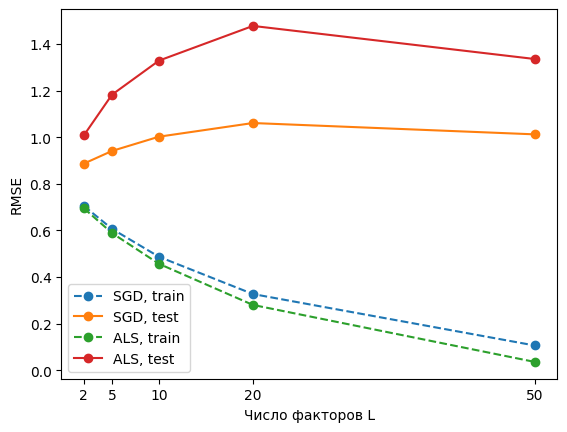

In [52]:
als_ranks = [2, 5, 10, 20, 50]
als_rank_scores, _ = sweep(train_als, train, test, "n_factors",als_ranks)
display(als_rank_scores.round(4))
for name, scores in [("SGD", sgd_rank_scores.loc[als_ranks]), ("ALS", als_rank_scores)]:
    plt.plot(scores.index, scores["Train RMSE"], "o--", label=f"{name}, train")
    plt.plot(scores.index, scores["Test RMSE"], "o-", label=f"{name}, test")
plt.xticks(als_ranks)
plt.gca().set(xlabel="Число факторов L", ylabel="RMSE")
plt.legend()
plt.show()

В этой сетке у SGD и ALS лучший вариант на test — два фактора. При большем числе факторов train RMSE падает, а test RMSE остаётся выше. После подбора шага и штрафа лучшее число факторов может поменяться.

### 3.3. Регуляризация

,Train RMSE,Test RMSE
reg,,
0.01,0.2897,2.0958
0.10,0.2804,1.4774
0.50,0.2907,1.1663
1.00,0.3123,1.0867


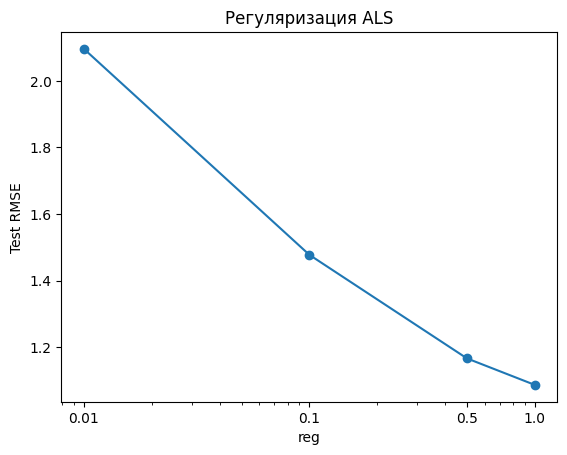

In [53]:
als_regs = [0.01, 0.1, 0.5, 1.0]
als_reg_scores, _ = sweep(train_als, train, test, "reg", als_regs)
display(als_reg_scores.round(4))
als_reg_scores["Test RMSE"].plot(marker="o", ylabel="Test RMSE", title="Регуляризация ALS")
plt.xscale("log")
plt.xticks(als_regs, [str(reg) for reg in als_regs])
plt.show()

С 20 факторами лучший проверенный штраф ALS — 1,0 с RMSE 1,0867. У SGD в его сетке лучший штраф — 0,1 с RMSE 0,8398. SGD применяет штраф на каждой оценке, ALS — раз на пользователя или фильм. У ALS ошибка ещё падает к краю сетки, поэтому дальше пробую более сильные штрафы.

## IV. Сравнение

### 4.1. Сводная таблица

Настройки выбираю на валидации внутри train. Сначала при 20 факторах подбираю шаг и штраф для SGD, а для ALS — штраф. Затем подбираю число факторов и заново обучаю модели на всём train. Ещё сравниваю оба метода при 20 факторах.

Засекаю только обучение. Компиляция Numba уже прошла выше. За эпоху выхода на минимум беру первую эпоху, когда test RMSE отличается от лучшего меньше чем на 0,001 или ровно на 0,001.

In [54]:
val_data = rating_arrays(val)


def val_rmse(trainer, **params):
    return model_rmse(val_data, trainer(fit_train, **params))


best_base_reg = min(
    baseline_regs,
    key=lambda reg: baseline_rmse(val, fit_baseline(fit_train, reg)),
)
sgd_settings = [(gamma, reg) for gamma in gammas for reg in sgd_regs]
best_gamma, best_sgd_reg = min(
    sgd_settings,
    key=lambda pair: val_rmse(train_sgd, n_factors=20, gamma=pair[0], reg=pair[1]),
)
best_als_reg = min(
    [*als_regs, 2, 5, 10, 20, 50],
    key=lambda reg: val_rmse(train_als, n_factors=20, reg=reg),
)
best_sgd_rank = min(
    sgd_ranks,
    key=lambda rank: val_rmse(train_sgd, n_factors=rank, gamma=best_gamma, reg=best_sgd_reg),
)
best_als_rank = min(
    als_ranks,
    key=lambda rank: val_rmse(train_als, n_factors=rank, reg=best_als_reg),
)

sgd_params = dict(n_factors=best_sgd_rank, gamma=best_gamma, reg=best_sgd_reg)
als_params = dict(n_factors=best_als_rank, reg=best_als_reg)


def convergence_epoch(curve):
    test_error = curve["Test RMSE"]
    return test_error[test_error <= test_error.min() + 0.001].index[0]


def timed_fit(trainer, **params):
    start = time.time()
    model = trainer(train, **params)
    return model, time.time() - start


best_baseline, seconds = timed_fit(fit_baseline, lambda_reg=best_base_reg)
rows = [["Baseline (МНК)", f"λ={best_base_reg}", baseline_rmse(test, best_baseline), seconds, "—"]]
test_data = rating_arrays(test)
best_curves = {}
matched = []

for label, trainer, params in [
    ("SVD (SGD)", train_sgd, sgd_params),
    ("ALS", train_als, als_params),
]:
    model, seconds = timed_fit(trainer, **params)
    curve = learning_curve(trainer, train, test, **params)
    best_curves[label] = curve
    settings = ", ".join(f"{name}={value}" for name, value in params.items())
    rows.append([label, settings, model_rmse(test_data, model), seconds, convergence_epoch(curve)])

    # Сравнение при 20 факторах.
    if params["n_factors"] != 20:
        model, seconds = timed_fit(trainer, **{**params, "n_factors": 20})
    matched.append([label, model_rmse(test_data, model), seconds])

summary = pd.DataFrame(rows, columns=[
    "Модель", "Параметры", "Test RMSE", "Обучение, с", "Эпоха выхода на минимум",
]).set_index("Модель")
display(summary.round(4))

matched = pd.DataFrame(matched, columns=["Модель при L=20", "Test RMSE", "Обучение, с"])
display(matched.round(4))

naive_mean_rmse = rmse(test["rating"], train["rating"].mean())
print(f"Test RMSE общего среднего train: {naive_mean_rmse:.4f}")

,Параметры,Test RMSE,"Обучение, с",Эпоха выхода на минимум
Модель,,,,
Baseline (МНК),λ=1,0.8558,1.1736,—
SVD (SGD),"n_factors=100, gamma=0.01, reg=0.1",0.8345,0.9900,68
ALS,"n_factors=50, reg=10",0.8413,3.7457,5


,Модель при L=20,Test RMSE,"Обучение, с"
0,SVD (SGD),0.8398,0.4718
1,ALS,0.8478,2.0766


Test RMSE общего среднего train: 1.0378


### 4.2. Сходимость SGD и ALS

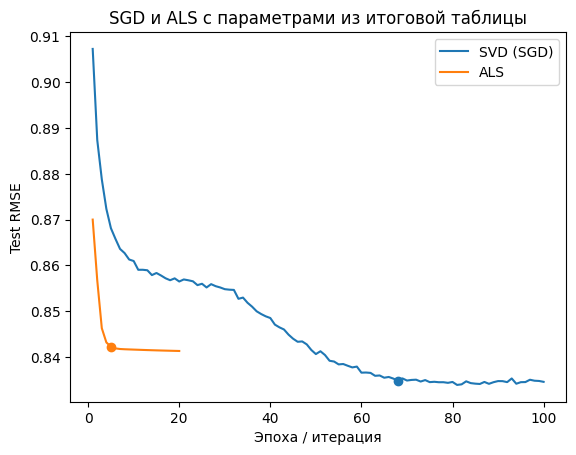

In [55]:
for label, curve in best_curves.items():
    plt.plot(curve.index, curve["Test RMSE"], label = label)
    epoch = convergence_epoch(curve)
    plt.scatter(epoch, curve.loc[epoch, "Test RMSE"])
plt.gca().set(xlabel="Эпоха / итерация", ylabel="Test RMSE", title="SGD и ALS с параметрами из итоговой таблицы")
plt.legend()
plt.show()

ALS подошёл к своему минимуму на 5-й итерации, SGD — на 68-й эпохе. ALS за раз пересчитывает целый блок параметров. SGD делает маленькое обновление после каждой оценки.

Итерация ALS дороже: нужно решить по системе для каждого пользователя и фильма. При 20 факторах полный прогон ALS здесь занял больше времени.

SGD удобен, когда новые оценки приходят постоянно или когда нужно быстро проходить по большому набору данных.

### 4.3. Итоговый вывод

На test лучше всего сработал SGD с L2: RMSE 0,8345. У ALS получилось 0,8413, у baseline — 0,8558. При одинаковых 20 факторах SGD тоже был немного точнее. Штраф помог использовать факторы и снизить переобучение.

Одно общее среднее дало RMSE 1,0378. Baseline снизил ошибку примерно на 0,18 за счёт поправок на пользователя и фильм.

На этих данных я бы выбрал SGD. Он дал меньшую ошибку и обучился быстрее ALS. Его проще обновлять по новым оценкам. Для пакетного обучения на большом наборе можно отдельно проверить ALS с параллельными обновлениями.

Для нового пользователя без оценок ещё нет персональных поправок. Обе модели могут дать общий прогноз с поправкой на фильм. Персонализация появится после первых оценок.